# Exercise 1 

In this exercise, we will practice how to read error messages in Python.

### Exercise 1(a) (2 points)

Load the `pandas` library.

In [5]:
import pandas as pd

### Exercise 1(b) (3 points)

Consider the below dictionary

```
data = {'x': ['1', '3.3', 4, '6.8', 10],
        'y': [3.2, 1.8, 8.5, 4.4, 5.3]}
```

Using the `data` dictionary, create a data frame called `df`

In [6]:
data = {'x': ['1', '3.3', 4, '6.8', 10],
        'y': [3.2, 1.8, 8.5, 4.4, 5.3]}

df = pd.DataFrame(data)
df

,x,y
0,1,3.2
1,3.3,1.8
2,4,8.5
3,6.8,4.4
4,10,5.3


### Exercise 1(c) (4 points)

Compute the average of the values in each row and store the result in a new column labeled `z`.

In [9]:
df["z"] = df.mean(axis=1)

print(df)

TypeError: can only concatenate str (not "float") to str

### Exercise 1(d) (5 points)

Print `.info()` of `df`, and modify `df` to compute the mean of row values.

In [10]:
df["x"] = pd.to_numeric(df["x"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       5 non-null      float64
 1   y       5 non-null      float64
dtypes: float64(2)
memory usage: 212.0 bytes


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       5 non-null      float64
 1   y       5 non-null      float64
dtypes: float64(2)
memory usage: 212.0 bytes


# Exercise 2

In this exercise, we will practice data visualiation with the `tips.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas` and `matplotlib`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
import sys
print(sys.executable)

/usr/local/bin/python3


In [7]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 21.2 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl (4.8 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matpl

### Exercise 2(b) (2 points)

Read the `tips.csv` data file and create a data frame called `tips`.

In [15]:
tips = pd.read_csv("tips.csv")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Exercise 2(c) (4 points)

Create a histogram of `total_bill`. Comment on the shape of the distributions.

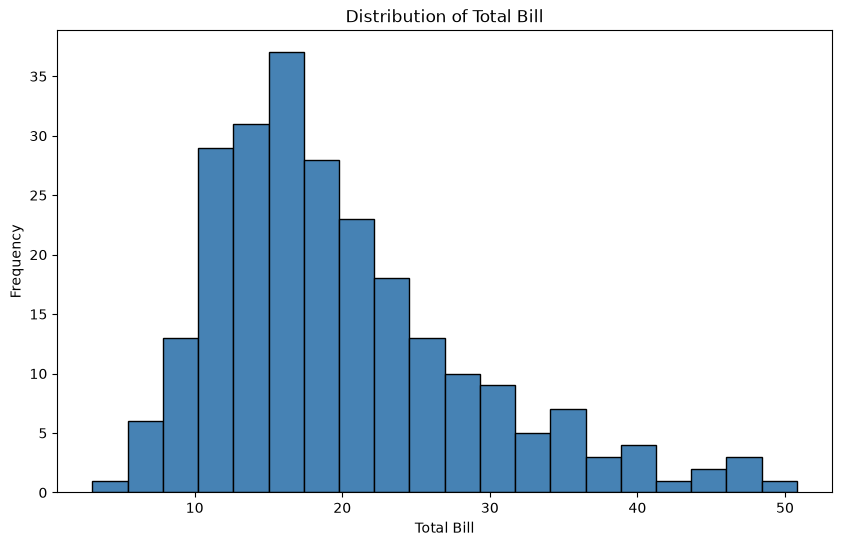

In [16]:
plt.figure(figsize=(10,6))

plt.hist(tips["total_bill"], bins=20, edgecolor="black", color="steelblue")
plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.show()

### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `total_bill` based on the day of the week.

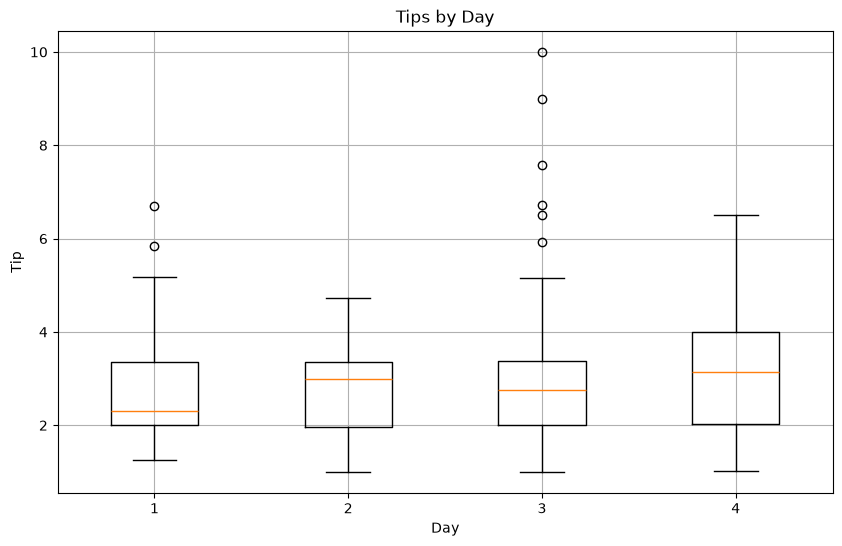

In [19]:
days = ["Thur", "Fri", "Sat", "Sun"]
data = [tips[tips["day"] == day]["tip"].sum() for day in days]

plt.figure(figsize=(10,6))

#Creating the side-by-side boxplot for the tips by day
plt.boxplot([tips[tips["day"] == day]["tip"] for day in days], label=days)
plt.title("Tips by Day")
plt.xlabel("Day")
plt.ylabel("Tip")
plt.grid(True)
plt.show()


### Exercise 2(e) (5 points)

Create a scatter-plot of `total_bill` and `tip`. Describe the plot.

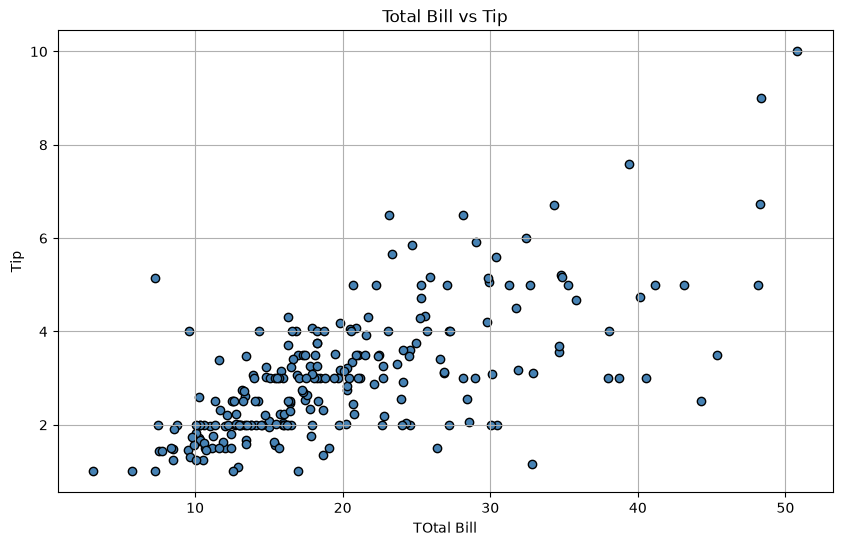

In [22]:
plt.figure(figsize=(10,6))

plt.scatter(tips["total_bill"], tips["tip"], color="steelblue", edgecolor="black")
plt.title("Total Bill vs Tip")
plt.xlabel("TOtal Bill")
plt.ylabel("Tip")
plt.grid(True)
plt.show()

# Exercise 3

In this exercise, we will practice debugging a data cleaning script written for the `tips.csv` data file. A colleague wrote the code below to compute the tip percentage (`tip` divided by `total_bill`, times 100) and compare it across days, but it contains several bugs.

```
import pandas as pd

tips = pd.read_csv('tips.csv')

# Step 1: tip percentage
tips['tip_pct'] = tips['tip'] / tips['Total_Bill'] * 100

# Step 2: average tip percentage by day
avg_by_day = tips.groupby('day')['tip_pct'].mean()
print('Average tip % on Saturday: ' + avg_by_day['Sat'])

# Step 3: weekend orders only
weekend = tips[(tips['day'] == 'Sat') or (tips['day'] == 'Sun')]
print(weekend.shape)
```

### Exercise 3(a) (4 points)

Run Step 1 in the cell below. Read the error message: what type of error is it, which line causes it, and why? Fix the code so that it runs.

In [28]:
import pandas as pd

tips = pd.read_csv('tips.csv')

# Step 1: tip percentage
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
tips

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765
...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,20.392697
240,27.18,2.00,Female,Yes,Sat,Dinner,2,7.358352
241,22.67,2.00,Male,Yes,Sat,Dinner,2,8.822232
242,17.82,1.75,Male,No,Sat,Dinner,2,9.820426


### Exercise 3(b) (4 points)

Run Step 2. Read the error message, explain what went wrong, and fix the code so that it prints the average tip percentage on Saturday rounded to two decimals.

In [26]:
#Step 2: average tip percentage by day
avg_by_day = tips.groupby('day')['tip_pct'].mean()
print('Average tip % on Saturday: ' + avg_by_day['Sat'])

KeyError: 'Column not found: tip_pct'

In [29]:
#Step 2: average tip percentage by day
avg_by_day = tips.groupby('day')['tip_pct'].mean()
print('Average tip & on Saturday: ' + str(avg_by_day['Sat']))

Average tip & on Saturday: 15.315171638777818


### Exercise 3(c) (4 points)

Run Step 3. Read the error message, explain what went wrong, and fix the code so that `weekend` contains only the Saturday and Sunday orders.

### Exercise 3(d) (4 points)

Not every bug raises an error. Use `.describe()` on `tip_pct` and `.isna().sum()` on `tips` to check that your results are reasonable (for example, tip percentages should be between 0 and 100 and there should be no missing values). Then use an `assert` statement to verify that `weekend` contains only `'Sat'` and `'Sun'`. Summarize what you found.